In [7]:
# Step 1: Libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from tensorflow.keras.utils import to_categorical

In [8]:
# Step 2: Load Data 
faces = fetch_olivetti_faces(shuffle=False)
X = faces.images      
y = faces.target      
print("Images:", X.shape)
print("Labels:", y.shape)
print("Number of people:", len(np.unique(y)))

Images: (400, 64, 64)
Labels: (400,)
Number of people: 40


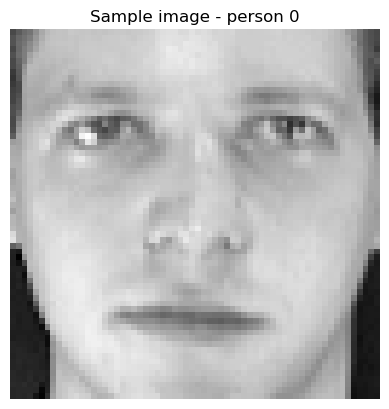

In [9]:
# Step 3: Sample image
plt.imshow(X[0], cmap="gray")
plt.title(f"Sample image - person {y[0]}")
plt.axis("off")
plt.show()

In [10]:
# Step 4: Training and testing sets (5 train / 5 test images per person)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, stratify=y, random_state=42)
print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("Train images per person:", np.unique(np.bincount(y_train)))  
print("Test images per person:", np.unique(np.bincount(y_test)))    

X_train: (200, 64, 64) X_test: (200, 64, 64)
Train images per person: [5]
Test images per person: [5]


In [11]:
# Step 5: Vector conversion (one-hot encode the target)
num_classes = 40
y_train_cat = to_categorical(y_train, num_classes)
y_test_cat = to_categorical(y_test, num_classes)
print("y_train_cat:", y_train_cat.shape) 
print("y_test_cat:", y_test_cat.shape)    

y_train_cat: (200, 40)
y_test_cat: (200, 40)


In [12]:
# Step 6: Reshape arrays (add a channel dimension for a CNN)
X_train = X_train.reshape(-1, 64, 64, 1)
X_test = X_test.reshape(-1, 64, 64, 1)
print("X_train reshaped:", X_train.shape)  
print("X_test reshaped:", X_test.shape)    

X_train reshaped: (200, 64, 64, 1)
X_test reshaped: (200, 64, 64, 1)
